# EDA: bộ UIT-VSFC, nhãn cảm xúc

Notebook này xem kỹ dữ liệu **trước khi train**, để các quyết định ở bước sau đều dựa trên số liệu đo được.

| Câu hỏi | Ảnh hưởng tới |
|---|---|
| Các nhãn có lệch nhau không? | Chọn metric (macro-F1), dùng `class_weight` |
| Một câu dài bao nhiêu token PhoBERT? | Chọn `max_len` khi tokenize |
| Có câu trùng giữa train và validation/test không? | Điểm test có bị "đẹp giả" do rò rỉ dữ liệu (leakage) không |
| Dữ liệu có token lạ (placeholder) nào? | Tiền xử lý trước khi đưa vào model |

**Quy tắc:** thống kê dùng để **ra quyết định** (số token PhoBERT, các lựa chọn `max_len`) chỉ tính trên **train**. Validation và test chỉ được đếm nhãn, đo độ dài và kiểm tra trùng lặp để mô tả dữ liệu, không dùng để chọn tham số.

**Về câu gốc:** giấy phép của UIT-VSFC chưa rõ (nhóm tác giả cung cấp cho nghiên cứu), nên notebook chỉ in khoảng 10 câu gốc làm ví dụ. Mọi phân tích khác chỉ hiển thị số đếm.

In [1]:
# Thiết lập chung: đường dẫn, seed, thư mục lưu hình, kiểu biểu đồ
import json
import re
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Notebook nằm trong notebooks/, còn code dùng chung nằm ở src/ của thư mục gốc.
# Thêm thư mục gốc vào sys.path để import được src.data dù chạy notebook từ đâu.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import LABEL_NAMES, SPLITS, load_split

SEED = 42  # truyền vào random_state khi lấy mẫu, để lần nào chạy cũng ra cùng các câu ví dụ

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", None)  # in đủ cả câu, không bị cắt thành "..."
summary = {"seed": SEED}  # gom các con số chính, cuối notebook ghi ra results/eda_summary.json

VI_NAMES = {"negative": "tiêu cực", "neutral": "trung tính", "positive": "tích cực"}

# Màu cố định cho từng tập, dùng chung cho mọi biểu đồ để người đọc không phải dò lại chú thích
SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
TEXT, TEXT_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "text.color": TEXT,
    "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10,
})


def fmt_vn(x, decimals=1):
    # Viết số thập phân kiểu Việt Nam (dấu phẩy) cho nhãn trên biểu đồ
    return f"{x:.{decimals}f}".replace(".", ",")

## 1. Đọc dữ liệu

`load_split` (trong `src/data.py`) đọc file Parquet đã tải ở bước 1 và trả về 2 cột: `text` (câu phản hồi của sinh viên) và `label` (0 = negative, 1 = neutral, 2 = positive).

In [2]:
dfs = {split: load_split(split) for split in SPLITS}
for split, df in dfs.items():
    print(f"{split:<10} {len(df):>6} câu")

train = dfs["train"].copy()  # bản sao để thêm cột (tách từ, số token) mà không sửa dữ liệu gốc
# Chỉ xem kiểu dữ liệu của 2 cột, không in hàng loạt câu gốc (giấy phép chưa rõ; ví dụ từng lớp ở mục 8)
train.dtypes

train       11426 câu
validation   1583 câu
test         3166 câu


text       str
label    int64
dtype: object

Kiểm tra nhanh định dạng. Biết dữ liệu đã được chuẩn hoá tới đâu (chữ thường? dấu câu đã tách?) thì mới biết bước tiền xử lý còn phải làm gì.

In [3]:
quality = []
for split, df in dfs.items():
    text = df["text"]
    quality.append({
        "tập": split,
        "số câu": len(df),
        "câu rỗng hoặc NaN": int(text.isna().sum() + (text.str.strip() == "").sum()),
        "câu có chữ hoa": int((text != text.str.lower()).sum()),
        # dấu câu đứng sát ngay sau chữ, vd "hành," (thay vì "hành ,")
        "câu có dấu câu dính liền chữ": int(text.str.contains(r"\w[.,!?;:]", regex=True).sum()),
        "câu có 2 dấu cách liền nhau": int(text.str.contains("  ", regex=False).sum()),
    })
pd.DataFrame(quality).set_index("tập")

,số câu,câu rỗng hoặc NaN,câu có chữ hoa,câu có dấu câu dính liền chữ,câu có 2 dấu cách liền nhau
tập,,,,,
train,11426,0,0,8,5
validation,1583,0,0,0,0
test,3166,0,0,1,3


## 2. Phân bố nhãn

Nếu một lớp quá ít, model có thể gần như bỏ qua lớp đó mà accuracy vẫn cao. Vì vậy cần biết tỉ lệ từng lớp trước khi chọn metric.

In [4]:
# Số câu mỗi nhãn trong từng tập (hàng = nhãn, cột = tập)
label_counts = pd.DataFrame({split: df["label"].value_counts().sort_index() for split, df in dfs.items()})
label_counts.index = LABEL_NAMES
label_pct = label_counts / label_counts.sum() * 100  # chia cho tổng của từng cột = % trong tập đó

pd.concat({"số câu": label_counts, "%": label_pct.round(2)}, axis=1)

số câu                       %                  
          train validation  test  train validation   test
negative   5325        705  1409  46.60      44.54  44.50
neutral     458         73   167   4.01       4.61   5.27
positive   5643        805  1590  49.39      50.85  50.22

In [5]:
# Tỉ lệ lớp nhiều nhất / lớp ít nhất trên train: con số gọn để nói về mức lệch lớp
train_counts = label_counts["train"]
imbalance_ratio = train_counts.max() / train_counts.min()
print(f"Train: lớp nhiều nhất ({train_counts.idxmax()}) gấp {imbalance_ratio:.1f} lần lớp ít nhất ({train_counts.idxmin()})")

summary["n_sentences"] = {split: len(df) for split, df in dfs.items()}
summary["label_distribution"] = {
    split: {name: {"count": int(label_counts.loc[name, split]), "pct": round(float(label_pct.loc[name, split]), 2)}
            for name in LABEL_NAMES}
    for split in SPLITS
}
summary["train_imbalance_ratio_max_over_min"] = round(float(imbalance_ratio), 2)

Train: lớp nhiều nhất (positive) gấp 12.3 lần lớp ít nhất (neutral)


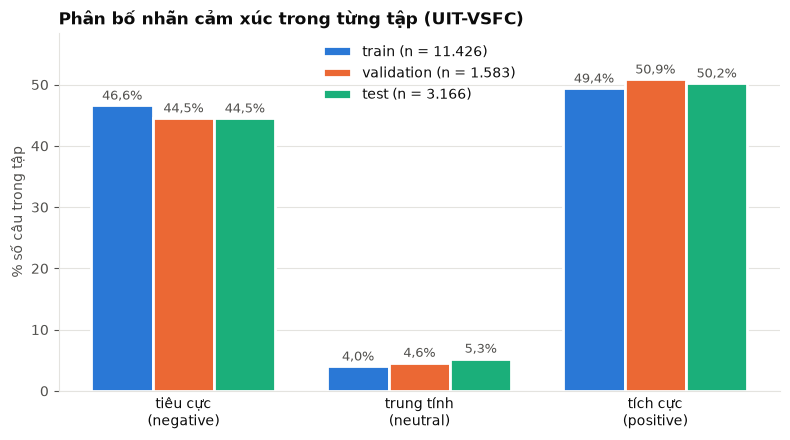

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(LABEL_NAMES))
width = 0.26
for i, split in enumerate(SPLITS):
    pct = label_pct[split].to_numpy()
    n = f"{len(dfs[split]):,}".replace(",", ".")
    bars = ax.bar(x + (i - 1) * width, pct, width, color=SPLIT_COLORS[split],
                  edgecolor=SURFACE, linewidth=2, label=f"{split} (n = {n})")
    # Ghi % trên đầu cột: ảnh tĩnh không rê chuột được nên cần thấy số trực tiếp
    ax.bar_label(bars, labels=[fmt_vn(p) + "%" for p in pct], padding=2, fontsize=9, color=TEXT_MUTED)

ax.set_xticks(x, [f"{VI_NAMES[name]}\n({name})" for name in LABEL_NAMES])
ax.tick_params(axis="x", colors=TEXT, length=0)
ax.set_ylabel("% số câu trong tập")
ax.set_ylim(0, label_pct.to_numpy().max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_title("Phân bố nhãn cảm xúc trong từng tập (UIT-VSFC)")
ax.legend(frameon=False, loc="upper center")
fig.tight_layout()
fig.savefig(FIG_DIR / "label_distribution.png", dpi=150)
plt.show()

## 3. Độ dài câu theo âm tiết

Tiếng Việt viết cách nhau theo **âm tiết** (`sinh viên` là 1 từ nhưng 2 âm tiết), nên tách theo khoảng trắng sẽ ra gần đúng số âm tiết. Lưu ý: dấu câu cũng được đếm là 1 phần tử, vì dữ liệu đã tách dấu câu ra bằng dấu cách (`"em xin cảm ơn ."` = 5 phần tử).

Đọc percentile: `p95 = 33` nghĩa là khoảng 95% số câu có ≤ 33 phần tử. Percentile tính bằng `np.percentile` (nội suy tuyến tính) nên có thể ra số lẻ.

In [7]:
PERCENTILES = [50, 90, 95, 99]


def describe_lengths(lengths):
    # Trả về p50/p90/p95/p99/max: chỉ nhìn trung bình sẽ không thấy "đuôi" câu dài
    lengths = np.asarray(lengths)
    stats = {f"p{p}": round(float(np.percentile(lengths, p)), 2) for p in PERCENTILES}
    stats["max"] = int(lengths.max())
    return stats


# str.split() không tham số: tách theo mọi khoảng trắng, 2 dấu cách liền nhau không tạo phần tử rỗng
syllable_len = {split: df["text"].str.split().str.len() for split, df in dfs.items()}
syllable_stats = {split: describe_lengths(lengths) for split, lengths in syllable_len.items()}
summary["length_syllables"] = syllable_stats
pd.DataFrame(syllable_stats).T

,p50,p90,p95,p99,max
train,11.0,26.0,33.0,52.00,159.0
validation,11.0,25.0,31.0,46.00,161.0
test,11.0,26.0,34.0,52.35,98.0


## 4. Tách từ bằng underthesea (chỉ tập train)

PhoBERT được pretrain trên văn bản **đã tách từ**: các âm tiết của một từ được nối bằng `_` (vd `sinh viên` → `sinh_viên`). Vì vậy văn bản phải được tách từ trước khi đưa vào tokenizer của PhoBERT. Project dùng `underthesea` (đã chốt ở bước 0).

Ở đây tách tập train để (1) đo thời gian chạy, (2) đếm số từ, (3) làm đầu vào cho tokenizer ở mục 5.

In [8]:
import warnings

# underthesea dùng tqdm; cảnh báo về thanh tiến trình trong Jupyter không ảnh hưởng kết quả nên tắt đi
warnings.filterwarnings("ignore", message="IProgress not found")

import underthesea
from underthesea import word_tokenize

start = time.perf_counter()
# format="text": trả về chuỗi, các âm tiết trong cùng một từ nối bằng "_"
train["text_seg"] = [word_tokenize(text, format="text") for text in train["text"]]
seg_seconds = time.perf_counter() - start

print(f"underthesea {underthesea.__version__}: tách {len(train):,} câu train mất {seg_seconds:.1f} giây "
      f"(~{len(train) / seg_seconds:,.0f} câu/giây, tính cả lần gọi đầu tiên phải nạp model)")

# Một câu ví dụ trước/sau khi tách từ; mục 5 dùng lại đúng câu này để xem tokenizer cắt ra sao
EXAMPLE_ROW = 1
print("Trước:", train["text"].iloc[EXAMPLE_ROW])
print("Sau:  ", train["text_seg"].iloc[EXAMPLE_ROW])

underthesea 9.5.0: tách 11,426 câu train mất 7.8 giây (~1,465 câu/giây, tính cả lần gọi đầu tiên phải nạp model)
Trước: nhiệt tình giảng dạy , gần gũi với sinh viên .
Sau:   nhiệt_tình giảng_dạy , gần_gũi với sinh_viên .


In [9]:
# Số từ sau khi tách = số phần tử cách nhau bởi khoảng trắng (một từ nhiều âm tiết giờ là 1 phần tử)
train["n_words"] = train["text_seg"].str.split().str.len()
word_stats = describe_lengths(train["n_words"])

summary["segmentation"] = {
    "tool": "underthesea.word_tokenize(text, format='text')",
    "underthesea_version": underthesea.__version__,
    "train_seconds": round(seg_seconds, 2),
}
summary["length_words_train"] = word_stats
pd.DataFrame({"âm tiết (train)": syllable_stats["train"], "từ sau tách (train)": word_stats}).T

,p50,p90,p95,p99,max
âm tiết (train),11.0,26.0,33.00,52.0,159.0
từ sau tách (train),9.0,21.0,26.75,42.0,122.0


## 5. Số token PhoBERT (chỉ tập train)

Tokenizer của PhoBERT nhận văn bản đã tách từ, rồi:
1. Cắt mỗi từ thành **subword** theo BPE. Từ có trong từ điển giữ nguyên, từ hiếm bị cắt thành nhiều mảnh (mảnh chưa phải cuối từ có đuôi `@@`).
2. Thêm token đặc biệt `<s>` ở đầu và `</s>` ở cuối câu.

`max_len` giới hạn chính con số cuối cùng này, nên phải đo trên văn bản **đã tách từ** và **tính cả 2 token đặc biệt**. Câu dài hơn `max_len` sẽ bị cắt mất phần cuối; câu ngắn hơn được đệm (padding) cho đủ độ dài, tốn thêm tính toán.

Chỉ đo trên **train**, vì `max_len` sẽ được chọn từ các số này; dùng test để chọn là gián tiếp "nhìn đề".

In [10]:
import transformers
from transformers import AutoConfig, AutoTokenizer

MODEL_NAME = "vinai/phobert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)  # chỉ tải tokenizer, không cần torch
config = AutoConfig.from_pretrained(MODEL_NAME)

# PhoBERT theo kiến trúc RoBERTa: 2 vị trí đầu của position embedding dành cho padding,
# nên câu dài tối đa = max_position_embeddings - 2. Đây là trần cứng của max_len.
model_max_tokens = config.max_position_embeddings - 2
print(f"transformers {transformers.__version__}, tokenizer: {type(tokenizer).__name__}")
print(f"max_position_embeddings = {config.max_position_embeddings} -> câu dài tối đa {model_max_tokens} token")

example = train["text_seg"].iloc[EXAMPLE_ROW]  # cùng câu ví dụ ở mục 4
print("\nVí dụ:", example)
print("Token:", tokenizer.convert_ids_to_tokens(tokenizer(example)["input_ids"]))

transformers 5.23.0, tokenizer: PhobertTokenizer
max_position_embeddings = 258 -> câu dài tối đa 256 token

Ví dụ: nhiệt_tình giảng_dạy , gần_gũi với sinh_viên .
Token: ['<s>', 'nhiệt_tình', 'giảng_dạy', ',', 'gần_gũi', 'với', 'sinh_viên', '.', '</s>']


In [11]:
start = time.perf_counter()
# Không truncation để đo độ dài thật; add_special_tokens mặc định True nên đã gồm <s> và </s>
input_ids = tokenizer(train["text_seg"].tolist())["input_ids"]
tok_seconds = time.perf_counter() - start
train["n_phobert"] = [len(ids) for ids in input_ids]
phobert_stats = describe_lengths(train["n_phobert"])

# <unk> = mảnh không có trong từ điển 64k của PhoBERT, model không hiểu được mảnh đó
n_unk = sum(ids.count(tokenizer.unk_token_id) for ids in input_ids)
n_total = int(train["n_phobert"].sum())
print(f"Tokenize {len(train):,} câu mất {tok_seconds:.1f} giây")
print(f"Token <unk>: {n_unk} / {n_total:,} token ({n_unk / n_total * 100:.3f}%)")

pd.DataFrame({"âm tiết": syllable_stats["train"], "từ sau tách": word_stats, "token PhoBERT": phobert_stats}).T

Tokenize 11,426 câu mất 1.0 giây
Token <unk>: 32 / 154,907 token (0.021%)


,p50,p90,p95,p99,max
âm tiết,11.0,26.0,33.00,52.0,159.0
từ sau tách,9.0,21.0,26.75,42.0,122.0
token PhoBERT,11.0,24.0,30.00,46.0,129.0


In [12]:
# Những từ (sau tách) nào sinh ra <unk>? Tokenize riêng từng từ để biết
unk_words = Counter()
for seg in train["text_seg"]:
    for word in seg.split():
        if tokenizer.unk_token_id in tokenizer(word, add_special_tokens=False)["input_ids"]:
            unk_words[word] += 1
print(unk_words.most_common(15))

[('khóa_học', 3), ('hợt', 3), ('nội_dụng', 2), ('full_điểm', 1), ('nghỉ_đẻ', 1), ('hô_mày', 1), ('cần_thiết_kế', 1), ('học_thể_dục', 1), ('chật_lượng', 1), ('chán_nản_tích', 1), ('gán_kết', 1), ('hình_tra_tấn', 1), ('thân_thiên', 1), ('củng_cổ', 1), ('kỳ_doubledot', 1)]


**Tỉ lệ câu bị cắt** ở các mức `max_len` ứng viên. Một câu bị cắt khi số token (đã gồm `<s>`, `</s>`) **lớn hơn** `max_len`. Bảng này chỉ trình bày lựa chọn; `max_len` sẽ được chốt ở bước tokenize.

In [13]:
MAX_LEN_CANDIDATES = [64, 96, 128, 160, 256]
n_tokens = train["n_phobert"]
truncation = pd.DataFrame([
    {
        "max_len": max_len,
        "số câu bị cắt": int((n_tokens > max_len).sum()),
        "% câu bị cắt": round(float((n_tokens > max_len).mean() * 100), 3),
        # Token bị bỏ đi: phần vượt quá max_len cộng lại trên mọi câu
        "token bị bỏ": int((n_tokens - max_len).clip(lower=0).sum()),
    }
    for max_len in MAX_LEN_CANDIDATES
])

summary["phobert_tokens_train"] = {
    "tokenizer": MODEL_NAME,
    "transformers_version": transformers.__version__,
    "input": "text đã tách từ bằng underthesea",
    "includes_special_tokens": True,
    "model_max_tokens": model_max_tokens,
    "tokenize_seconds": round(tok_seconds, 2),
    "unk_tokens": n_unk,
    "total_tokens": n_total,
    **phobert_stats,
}
summary["truncation_train"] = truncation.to_dict(orient="records")
truncation

,max_len,số câu bị cắt,% câu bị cắt,token bị bỏ
0,64,27,0.236,333
1,96,2,0.018,50
2,128,1,0.009,1
3,160,0,0.000,0
4,256,0,0.000,0


Biểu đồ: bên trái so sánh độ dài (âm tiết) của 3 tập, để xem train có cùng "dáng" với validation/test không. Bên phải là số token PhoBERT trên train, kèm các mức `max_len` ứng viên.

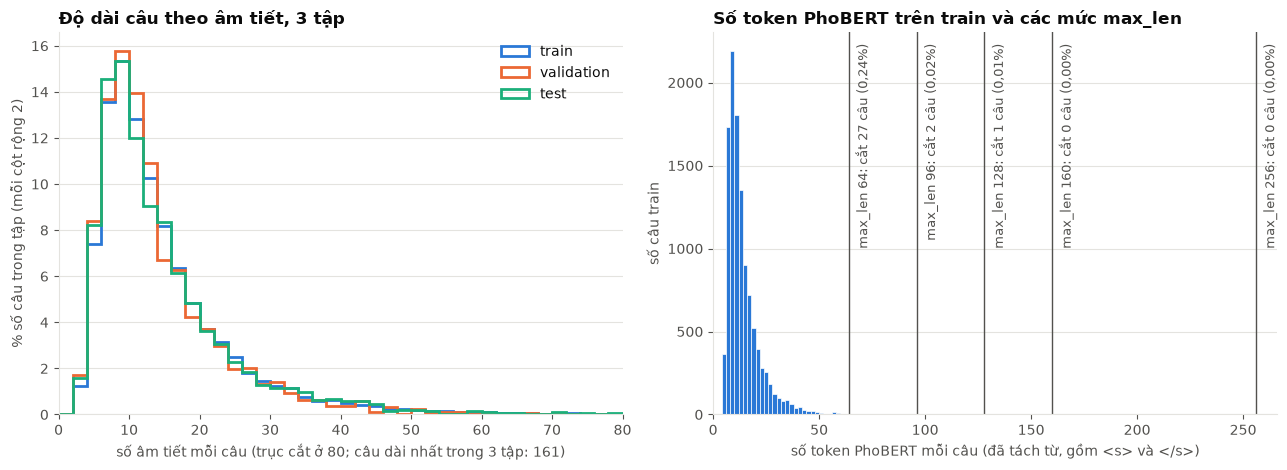

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Trái: % số câu theo từng khoảng độ dài (vẽ theo % vì 3 tập có số câu rất khác nhau)
X_LIMIT = 80
bins = np.arange(0, max(s.max() for s in syllable_len.values()) + 3, 2)
for split in SPLITS:
    lengths = syllable_len[split]
    ax1.hist(lengths, bins=bins, weights=np.full(len(lengths), 100 / len(lengths)),
             histtype="step", linewidth=2, color=SPLIT_COLORS[split], label=split)
ax1.set_xlim(0, X_LIMIT)
longest = max(s.max() for s in syllable_len.values())
ax1.set_xlabel(f"số âm tiết mỗi câu (trục cắt ở {X_LIMIT}; câu dài nhất trong 3 tập: {longest})")
ax1.grid(axis="x", visible=False)
ax1.set_ylabel("% số câu trong tập (mỗi cột rộng 2)")
ax1.set_title("Độ dài câu theo âm tiết, 3 tập")
ax1.legend(frameon=False)

# Phải: số token PhoBERT trên train + vạch các mức max_len
ax2.hist(n_tokens, bins=np.arange(0, n_tokens.max() + 3, 2), color=SPLIT_COLORS["train"],
         edgecolor=SURFACE, linewidth=0.5)
ax2.set_xlim(0, max(MAX_LEN_CANDIDATES) + 10)
top = ax2.get_ylim()[1]
for max_len, n_cut, pct_cut in truncation[["max_len", "số câu bị cắt", "% câu bị cắt"]].itertuples(index=False):
    ax2.axvline(max_len, color=TEXT_MUTED, linewidth=1)
    ax2.text(max_len + 3, top * 0.97, f"max_len {max_len}: cắt {n_cut} câu ({fmt_vn(pct_cut, 2)}%)",
             rotation=90, va="top", ha="left", fontsize=9, color=TEXT_MUTED)
ax2.set_xlabel("số token PhoBERT mỗi câu (đã tách từ, gồm <s> và </s>)")
ax2.set_ylabel("số câu train")
ax2.grid(axis="x", visible=False)  # bỏ lưới dọc để không lẫn với vạch max_len
ax2.set_title("Số token PhoBERT trên train và các mức max_len")

fig.tight_layout()
fig.savefig(FIG_DIR / "length_distribution.png", dpi=150)
plt.show()

## 6. Câu trùng lặp và rò rỉ dữ liệu (leakage)

- Nếu một câu của test **cũng nằm trong train**, model chỉ cần "nhớ" là đoán đúng, nên điểm test sẽ cao hơn năng lực thật.
- Nếu cùng một câu xuất hiện nhiều lần trong train mà **nhãn khác nhau**, đó là nhiễu nhãn: model không thể đúng cả hai.

So khớp ở 3 mức chuẩn hoá, từ chặt tới lỏng:
1. `strip`: bỏ khoảng trắng ở 2 đầu câu.
2. `strip + lower`: thêm chuyển về chữ thường.
3. `lower + bỏ dấu câu`: thêm thay mọi ký tự không phải chữ/số bằng dấu cách rồi gộp khoảng trắng. Mức này bắt các câu chỉ khác nhau ở dấu câu, vd `"em xin cảm ơn !"` và `"em xin cảm ơn ."`.

Nhãn của validation/test ở đây chỉ dùng để đếm xem câu trùng có cùng nhãn với train không (đo mức rò rỉ), không dùng để chọn tham số.

In [15]:
NORMALIZERS = {
    "strip": lambda s: s.str.strip(),
    "strip + lower": lambda s: s.str.strip().str.lower(),
    # [^\w\s] = ký tự không phải chữ/số/khoảng trắng, tức là dấu câu; split + join để gộp khoảng trắng thừa
    "lower + bỏ dấu câu": lambda s: s.str.lower().str.replace(r"[^\w\s]", " ", regex=True).str.split().str.join(" "),
}

within_train = []
for name, normalize in NORMALIZERS.items():
    key = normalize(train["text"])
    n_labels = train.groupby(key)["label"].nunique()  # mỗi câu (sau chuẩn hoá) có bao nhiêu nhãn khác nhau
    within_train.append({
        "chuẩn hoá": name,
        "số câu lặp lại (≥ 2 lần)": int((key.value_counts() > 1).sum()),
        "số dòng thừa (bản sao)": int(key.duplicated().sum()),  # lần xuất hiện thứ 2, 3... của cùng một câu
        "câu lặp có nhãn mâu thuẫn": int((n_labels > 1).sum()),
    })
within_train = pd.DataFrame(within_train).set_index("chuẩn hoá")
within_train

,số câu lặp lại (≥ 2 lần),số dòng thừa (bản sao),câu lặp có nhãn mâu thuẫn
chuẩn hoá,,,
strip,1,1,1
strip + lower,1,1,1
lower + bỏ dấu câu,82,85,2


In [16]:
overlap = []
for name, normalize in NORMALIZERS.items():
    train_key = normalize(train["text"])
    train_labels = train.groupby(train_key)["label"].agg(set)  # câu -> tập nhãn của nó trong train
    for split in ["validation", "test"]:
        other = dfs[split]
        other_key = normalize(other["text"])
        in_train = other_key.isin(train_labels.index)
        same_label = sum(label in train_labels[k] for k, label in zip(other_key[in_train], other["label"][in_train]))
        overlap.append({
            "chuẩn hoá": name,
            "tập": split,
            "số dòng có trong train": int(in_train.sum()),
            "% của tập": round(float(in_train.mean() * 100), 2),
            "trong đó cùng nhãn với train": int(same_label),
        })
overlap = pd.DataFrame(overlap).set_index(["chuẩn hoá", "tập"])

summary["duplicates_within_train"] = within_train.reset_index().to_dict(orient="records")
summary["overlap_with_train"] = overlap.reset_index().to_dict(orient="records")
overlap

số dòng có trong train  % của tập  \
chuẩn hoá          tập                                             
strip              validation                       0       0.00   
                   test                             0       0.00   
strip + lower      validation                       0       0.00   
                   test                             0       0.00   
lower + bỏ dấu câu validation                      27       1.71   
                   test                            46       1.45   

                               trong đó cùng nhãn với train  
chuẩn hoá          tập                                       
strip              validation                             0  
                   test                                   0  
strip + lower      validation                             0  
                   test                                   0  
lower + bỏ dấu câu validation                            26  
                   test                                  45

Câu lặp có nhãn mâu thuẫn: chỉ in câu lặp **nguyên văn** (mức `strip`, có đúng 1 câu). Các câu mâu thuẫn ở mức bỏ dấu câu chỉ được đếm trong bảng trên.

In [17]:
# Mỗi câu (mức strip) -> danh sách nhãn của mọi lần nó xuất hiện; giữ câu xuất hiện từ 2 lần trở lên
strip_key = NORMALIZERS["strip"](train["text"])
labels_per_text = train.groupby(strip_key)["label"].agg(lambda s: [LABEL_NAMES[k] for k in s])
labels_per_text[labels_per_text.str.len() > 1].to_frame("các nhãn trong train")

,các nhãn trong train
text,
"thầy dạy hay , tuy nhiên còn nhiều chỗ chưa thật sự giải đáp hoàn toàn cho sinh viên vì chưa đủ thời gian .","[positive, negative]"


Một ví dụ câu test trùng với train ở mức bỏ dấu câu (cặp được nhắc ở phần Nhận xét). Chỉ in 1 cặp để minh hoạ; số lượng đầy đủ nằm ở bảng trên.

In [18]:
loose = NORMALIZERS["lower + bỏ dấu câu"]
test = dfs["test"]
example_test = test[test["text"] == "thầy rất tận tình !"].iloc[0]
# Tìm câu train có cùng dạng sau chuẩn hoá lỏng với câu test trên
example_train = train[loose(train["text"]) == loose(pd.Series([example_test["text"]]))[0]].iloc[0]
pd.DataFrame({
    "tập": ["test", "train"],
    "câu": [example_test["text"], example_train["text"]],
    "nhãn": [LABEL_NAMES[example_test["label"]], LABEL_NAMES[example_train["label"]]],
})

,tập,câu,nhãn
0,test,thầy rất tận tình !,positive
1,train,thầy rất tận tình .,positive


## 7. Token đặc biệt (placeholder) và token phổ biến

UIT-VSFC thay một số nội dung (tên người, biểu tượng cảm xúc, một số ký hiệu) bằng các chuỗi chữ Latin. Không đoán trước, mà tìm trong dữ liệu: liệt kê các token **chỉ gồm a–z và chữ số** (không có dấu tiếng Việt), dài **≥ 7 ký tự**, đổi dãy chữ số thành `<số>` để gom các token cùng dạng.

In [19]:
train_tokens = Counter(token for text in train["text"] for token in text.split())

shapes = Counter()
for token, count in train_tokens.items():
    if len(token) >= 7 and re.fullmatch(r"[a-z0-9]+", token) and re.search(r"[a-z]", token):
        shapes[re.sub(r"\d+", "<số>", token)] += count
print(shapes.most_common(40))

[('wzjwz<số>', 230), ('doubledot', 85), ('deadline', 42), ('seminar', 39), ('colonsmile', 27), ('website', 26), ('fraction', 19), ('courses', 17), ('speaking', 14), ('colonsmilesmile', 12), ('colonsad', 11), ('internet', 9), ('coloncontemn', 9), ('facebook', 8), ('colonlove', 7), ('project', 7), ('listening', 6), ('windows', 5), ('colonbigsmile', 5), ('training', 5), ('dotdotdot', 5), ('android', 4), ('wireshark', 4), ('colonsmallsmile', 4), ('colondoublesurprise', 3), ('colonhihi', 3), ('framework', 3), ('grammar', 3), ('youtube', 3), ('servlet', 2), ('silverlight', 2), ('cplusplus', 2), ('pattern', 2), ('cassette', 2), ('trigger', 2), ('smartphone', 2), ('<số>doubledot<số>', 2), ('translate', 2), ('directx', 2), ('it<số>dote<số>', 2)]


Trong danh sách trên có từ tiếng Anh bình thường (`deadline`, `seminar`, `website`...) và các chuỗi lạ. Đọc các câu chứa chuỗi lạ thì thấy 5 họ placeholder dưới đây. Cột "ý nghĩa" là **suy đoán từ ngữ cảnh**; trang dữ liệu không mô tả các placeholder này.

In [20]:
# (tên họ, regex nhận diện, ý nghĩa suy đoán). Thứ tự quan trọng: "doubledot" phải xét trước "dot".
PLACEHOLDER_FAMILIES = [
    ("wzjwz<số>", r"wzjwz\d+", "tên người, thường đứng sau 'thầy'/'cô'"),
    ("colon...", r"^colon", "biểu tượng cảm xúc (colonsmile, colonsad, ...)"),
    ("doubledot", r"doubledot", "dấu ':' (vd 11doubledot55 = 11:55)"),
    ("dot", r"dot", "dấu '.' (vd 1dot5 = 1.5, dotdotdot = ...)"),
    ("fraction", r"^fraction$", "dấu '/' (vd 'thầy fraction cô' = thầy/cô)"),
]


def placeholder_family(token):
    # Trả về tên họ placeholder của token, hoặc None nếu là token bình thường
    for family, pattern, _ in PLACEHOLDER_FAMILIES:
        if re.search(pattern, token):
            return family
    return None


# underthesea có thể ghép placeholder với âm tiết bên cạnh thành 1 "từ" (vd "kỳ_doubledot")
merged = Counter()
for seg in train["text_seg"]:
    for word in seg.split():
        if "_" in word:
            for part in word.split("_"):
                if placeholder_family(part):
                    merged[placeholder_family(part)] += 1

family_rows = []
for family, pattern, meaning in PLACEHOLDER_FAMILIES:
    tokens = {t: c for t, c in train_tokens.items() if placeholder_family(t) == family}
    family_rows.append({
        "họ": family,
        "ý nghĩa (suy đoán)": meaning,
        "số lần xuất hiện": sum(tokens.values()),
        "số câu": int(train["text"].map(lambda s: any(placeholder_family(t) == family for t in s.split())).sum()),
        "số dạng khác nhau": len(tokens),
        "bị underthesea ghép vào từ khác": merged[family],
    })
families = pd.DataFrame(family_rows).set_index("họ")
summary["placeholder_families_train"] = families.reset_index().to_dict(orient="records")
families

,ý nghĩa (suy đoán),số lần xuất hiện,số câu,số dạng khác nhau,bị underthesea ghép vào từ khác
họ,,,,,
wzjwz<số>,"tên người, thường đứng sau 'thầy'/'cô'",238,211,233,2
colon...,"biểu tượng cảm xúc (colonsmile, colonsad, ...)",85,85,12,9
doubledot,dấu ':' (vd 11doubledot55 = 11:55),87,85,3,9
dot,"dấu '.' (vd 1dot5 = 1.5, dotdotdot = ...)",43,41,13,3
fraction,dấu '/' (vd 'thầy fraction cô' = thầy/cô),19,18,1,2


In [21]:
# Top 15 placeholder cụ thể, kèm cách tokenizer PhoBERT cắt chúng thành subword
placeholder_counts = Counter({t: c for t, c in train_tokens.items() if placeholder_family(t)})
top_placeholders = pd.DataFrame([
    {"token": token, "họ": placeholder_family(token), "số lần": count,
     "subword PhoBERT": " ".join(tokenizer.tokenize(token))}
    for token, count in placeholder_counts.most_common(15)
])
summary["top_placeholders_train"] = top_placeholders[["token", "họ", "số lần"]].to_dict(orient="records")  # không lưu cột subword
top_placeholders

,token,họ,số lần,subword PhoBERT
0,doubledot,doubledot,85,dou@@ ble@@ dot
1,colonsmile,colon...,27,co@@ lon@@ sm@@ ile
2,fraction,fraction,19,f@@ rac@@ tion
3,dot,dot,18,dot
4,colonsmilesmile,colon...,12,co@@ lon@@ s@@ mil@@ es@@ m@@ ile
5,colonsad,colon...,11,co@@ lon@@ sad
6,coloncontemn,colon...,9,co@@ lon@@ con@@ tem@@ n
7,vdotv,dot,8,v@@ do@@ tv
8,colonlove,colon...,7,co@@ lon@@ love
9,colonbigsmile,colon...,5,co@@ lon@@ bi@@ g@@ sm@@ ile


In [22]:
# 30 token (tách theo khoảng trắng) xuất hiện nhiều nhất trong train
n_all_tokens = sum(train_tokens.values())
top_tokens = pd.DataFrame(train_tokens.most_common(30), columns=["token", "số lần"])
top_tokens["% tổng số token"] = (top_tokens["số lần"] / n_all_tokens * 100).round(2)
top_tokens.index = top_tokens.index + 1  # xếp hạng bắt đầu từ 1
summary["top30_tokens_train"] = top_tokens[["token", "số lần"]].to_dict(orient="records")
print(f"Train có {n_all_tokens:,} token, {len(train_tokens):,} token khác nhau")
top_tokens

Train có 163,492 token, 2,514 token khác nhau


,token,số lần,% tổng số token
1,.,11009,6.73
2,",",6827,4.18
3,viên,4803,2.94
4,giảng,3711,2.27
5,dạy,3156,1.93
6,thầy,3095,1.89
7,sinh,3082,1.89
8,học,2940,1.80
9,bài,2336,1.43
10,tình,2266,1.39


## 8. Ví dụ từng lớp (train, seed 42)

Đọc câu thật giúp hiểu mỗi nhãn nghĩa là gì, và sau này dễ giải thích vì sao model nhầm. Chỉ in 2 câu mỗi lớp vì giấy phép dữ liệu chưa rõ.

In [23]:
shown = train.groupby("label").sample(2, random_state=SEED)  # mỗi nhãn lấy ngẫu nhiên 2 câu
shown.assign(label_name=shown["label"].map(dict(enumerate(LABEL_NAMES))))[["label_name", "text"]]

,label_name,text
3983,negative,"một số bài tập không rõ , không đi sâu ."
10787,negative,không sửa bài chi tiết vì nghĩ nó dễ so với học sinh .
3746,neutral,thầy trực phòng thực hành cũng đã bảo về và vào phòng tắt máy lạnh .
12,neutral,"đang dạy thầy wzjwz208 đi qua nước ngoài giữa chừng , thầy wzjwz209 dạy thay ."
9952,positive,"phương pháp truyền đạt tốt , đảm bảo đủ lượng kiến thức cung cấp cho sinh viên ."
2174,positive,cách dạy hay .


## 9. Lưu số liệu tóm tắt

Ghi các con số chính ra `results/eda_summary.json` để README và các bước sau trích dẫn đúng số, không phải chép tay.

In [24]:
summary_path = ROOT / "results" / "eda_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)  # ensure_ascii=False để giữ nguyên chữ tiếng Việt
print("Đã ghi", summary_path.relative_to(ROOT))

Đã ghi results\eda_summary.json


## Nhận xét

Chỉ ghi những gì đã đo ở trên. Số thập phân viết kiểu Việt Nam (dấu phẩy).

**Nhãn**
- Lớp trung tính rất ít: 458 câu train (4,01%), 73 câu validation (4,61%), 167 câu test (5,27%). Trên train, lớp positive (5.643 câu) gấp 12,3 lần lớp neutral. Negative và positive gần cân bằng (46,6% và 49,4% trên train).
- Tỉ lệ từng lớp ở 3 tập chênh nhau tối đa 2,1 điểm phần trăm (negative: 46,6% ở train, 44,5% ở test).
- Một model không bao giờ đoán đúng câu trung tính chỉ mất tối đa 5,27% accuracy trên test, nên accuracy gần như không phản ánh lớp này. Macro-F1 (trung bình F1 của 3 lớp, mỗi lớp nặng như nhau) thì phản ánh được.

**Độ dài và `max_len`**
- Câu ngắn: trung vị 11 âm tiết ở cả 3 tập, p95 từ 31 đến 34. Dài nhất: 159 (train), 161 (validation), 98 (test). Phân bố độ dài của 3 tập gần trùng nhau (biểu đồ trái).
- Trên train, sau khi tách từ và tokenize (gồm `<s>`, `</s>`): p50 = 11, p90 = 24, p95 = 30, p99 = 46, max = 129 token. PhoBERT nhận tối đa 256 token.
- Các lựa chọn `max_len` (đo trên train):

| `max_len` | câu train bị cắt | token bị bỏ |
|---|---|---|
| 64 | 27 (0,24%) | 333 |
| 96 | 2 (0,02%) | 50 |
| 128 | 1 (0,01%) | 1 |
| 160 | 0 | 0 |
| 256 | 0 | 0 |

- Đánh đổi: `max_len` nhỏ thì vài câu dài bị cắt mất phần cuối. `max_len` lớn thì không cắt câu nào, nhưng nếu đệm mọi câu tới đúng `max_len` thì một câu 11 token cũng thành 64 hay 256 token, tốn thêm bộ nhớ GPU và thời gian (chi phí self-attention tăng theo bình phương độ dài). Nếu chỉ đệm tới câu dài nhất trong từng batch thì `max_len` chỉ còn vai trò giới hạn cắt.
- 32 trên 154.907 token PhoBERT của train là `<unk>` (0,021%).

**Trùng lặp và rò rỉ dữ liệu**
- Mức `strip` và `strip + lower` cho cùng kết quả (dữ liệu vốn đã toàn chữ thường): train chỉ có 1 câu lặp lại, xuất hiện 2 lần với 2 nhãn khác nhau (positive và negative). Không câu nào của validation hay test trùng với train.
- Mức bỏ dấu câu: train có 82 câu lặp (85 dòng thừa), 2 câu có nhãn mâu thuẫn (thêm cặp `em xin cảm ơn .` positive / `em xin cảm ơn !` neutral). 27 câu validation (1,71%) và 46 câu test (1,45%) trùng một câu train, trong đó 26 và 45 câu cùng nhãn với train. Vì dữ liệu đã toàn chữ thường, các cặp trùng ở mức này chỉ khác nhau ở dấu câu, ký hiệu hoặc khoảng trắng, vd `thầy rất tận tình !` (test) và `thầy rất tận tình .` (train).
- Nếu model "nhớ" đúng 45 câu test trùng nhãn đó, phần đóng góp vào accuracy test tối đa là 45 / 3.166 ≈ 1,4 điểm phần trăm.

**Placeholder** (ý nghĩa là suy đoán từ ngữ cảnh)
- Trên train có 5 họ: `wzjwz<số>` (tên người) 238 lần trong 211 câu, với 233 mã khác nhau; `colon...` (biểu tượng cảm xúc) 85 lần, 12 dạng, nhiều nhất `colonsmile` 27 lần; `doubledot` (dấu `:`) 87 lần; `dot` (dấu `.`) 43 lần, 13 dạng; `fraction` (dấu `/`) 19 lần.
- Tokenizer PhoBERT cắt placeholder thành nhiều mảnh: `colonsmile` thành 4 mảnh, `wzjwz83` thành 6 mảnh, `doubledot` thành 3 mảnh. Riêng `dot` giữ nguyên 1 token.
- underthesea ghép placeholder với âm tiết bên cạnh thành một "từ" tổng cộng 25 lần (vd `kỳ_doubledot`).

**Khác**
- Dữ liệu đã chữ thường hết, không có câu rỗng; dấu câu gần như luôn được tách bằng dấu cách (chỉ 8 câu train có dấu câu dính liền chữ).
- Train có 163.492 token (tách theo khoảng trắng) nhưng chỉ 2.514 token khác nhau. Đứng đầu là `.`, `,` và các âm tiết `viên`, `giảng`, `dạy`, `thầy`, `sinh`.
- underthesea tách 11.426 câu train mất từ khoảng 5 đến 14 giây qua các lần chạy trên cùng một máy (dao động theo tải của máy; số của lần chạy này in ở mục 4). Tokenizer PhoBERT mất dưới 2 giây.